# C0 · does narrowing a target axis reduce the error along it? Equivalence test (free analysis 2 of 4)

**Why.** At both tiers the narrowed (short) axes of the arm A ovals showed no change in error spread, while widened axes
lost precision. "No significant change" is not evidence of no change. This notebook bounds the narrowing effect from above
with an equivalence (TOST) test, which is the quantitative statement behind "target shape cannot buy precision".

**Status: exploratory, not pre-registered.** The margins below were fixed in this notebook before it was first run:

* **Slope margin ±0.10:** the plan's own "strength" margin for α (P0a). A narrowing slope inside ±0.10 means that, along the
  narrowed axis, transfer is below the level the plan called established.
* **Effect margin ±0.03 log SD at ratio 4:** the ratio-4 short axis is half the round width (x = log 0.5); a change of less than
  3 % in SD there is too small to matter for the MDT gains.

**Model.** Per landmark, OLS on its usable A∥ and A⊥ observations:
Δ log SD = c_i + a_wide,i · max(x, 0) + a_narrow,i · min(x, 0), where x = log(σ_d/σ₀). a_narrow > 0 means narrowing reduces
the spread (the MDT mechanism); a_wide > 0 means widening increases it. The pooled slopes are means over landmarks (as for α
in §10), with t-based 90 % intervals (TOST at 5 %). A second fit splits a_narrow by orientation: narrowing along the baseline
**minor** axis (A∥ short axis, direction v) and along the baseline **major** axis (A⊥ short axis, direction u); the latter is
the direction MDT would narrow at a landmark whose largest error lies along a measurement-sensitive direction.

In [1]:
ANALYSIS = "narrowing_equivalence"
import os, json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def _repo_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "weights").is_dir() and (q / "data").is_dir():
            return q
    return None

_REPO = _repo_root()
W_ROOT = Path(os.environ.get("C0_WEIGHTS", "/tf/weights/C0" if os.path.isdir("/tf/weights/C0") else str(_REPO / "weights" / "C0")))
OUT = W_ROOT / "analyses" / ANALYSIS
OUT.mkdir(parents=True, exist_ok=True)
PD = "quadratic"
TIERS = {"High": {"net": "UNet-64", "sigma0_px": 5.0, "protocol": "093467c2293e4792", "arm": "47b9c6388cce8c42"},
         "Medium": {"net": "UNet-32", "sigma0_px": 5.0 * 2 ** 0.5, "protocol": "09b9ae2a23fe2266", "arm": "6505f2d9c645689e"}}
COLORS = {"High": "#0072B2", "Medium": "#D55E00"}
MIN_OBS = 8
MARGIN_SLOPE, MARGIN_R4 = 0.10, 0.03
X_R4 = -math.log(2)

def load_obs(t):
    agg = W_ROOT / f"ISBI2015_{t}" / "arm_A_summary"
    pool = json.loads((agg / "alpha_pooled.json").read_text())
    assert pool["protocol_hash"] == TIERS[t]["protocol"] and pool["arm_hash"] == TIERS[t]["arm"], f"{t}: unexpected arm A analysis"
    o = pd.read_csv(agg / "arm_A_axis_observations.csv")
    o = o[o.decoder == PD].copy()
    o["usable"] = o.usable.astype(bool)
    return o

OBS = {t: load_obs(t) for t in TIERS}
NAMES = pd.read_csv(W_ROOT / "ISBI2015_High" / "arm_A_summary" / "alpha_by_landmark.csv").set_index("landmark").name

## 1. Per-landmark piecewise fits

In [2]:
def ols(X, y):
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    r = y - X @ b
    dof = len(y) - X.shape[1]
    cov = (r @ r / dof) * np.linalg.inv(X.T @ X)
    return b, np.sqrt(np.diag(cov))

rows = []
for t, o in OBS.items():
    for lm, g in o[o.usable].groupby("landmark"):
        if len(g) < MIN_OBS:
            continue
        x, y = g.x.values, g.dlog_sd.values
        xp, xn = np.clip(x, 0, None), np.clip(x, None, 0)
        b, se = ols(np.column_stack([np.ones_like(x), xp, xn]), y)
        par, perp = (g.arm == "Apar").values, (g.arm == "Aperp").values
        b2, se2 = ols(np.column_stack([np.ones_like(x), xp, xn * par, xn * perp]), y)
        r4 = g[np.isclose(g.x, X_R4)]
        rows.append({"tier": t, "landmark": lm, "name": NAMES[lm], "n_obs": len(g), "c": b[0],
                     "a_wide": b[1], "se_wide": se[1], "a_narrow": b[2], "se_narrow": se[2],
                     "a_narrow_minor_axis": b2[2], "a_narrow_major_axis": b2[3],
                     "r4_short_dlogsd": r4.dlog_sd.mean(), "r4_short_minor_axis": r4[r4.arm == "Apar"].dlog_sd.mean(),
                     "r4_short_major_axis": r4[r4.arm == "Aperp"].dlog_sd.mean(), "n_r4": len(r4)})
LM = pd.DataFrame(rows)
LM.round(4).to_csv(OUT / "narrowing_by_landmark.csv", index=False)
LM.pivot_table(index="name", columns="tier", values=["a_narrow", "a_wide"]).round(3)

a_narrow        a_wide       
tier                       High Medium   High Medium
name                                                
anterior nasal spine      0.019  0.034  0.151  0.133
articulare               -0.052  0.039  0.152  0.140
gnathion                 -0.082  0.025  0.261  0.295
lower incisal incision   -0.046 -0.070  0.244  0.231
lower lip                 0.037 -0.001  0.049  0.132
menton                   -0.039 -0.018  0.065  0.091
nasion                   -0.184 -0.096  0.197  0.130
orbitale                 -0.025  0.015  0.088  0.032
pogonion                 -0.021 -0.035  0.222  0.416
posterior nasal spine     0.002  0.064  0.183  0.154
sella                     0.017 -0.072  0.158  0.248
subnasale                 0.021 -0.079  0.057  0.175
subspinale (A)            0.023  0.044  0.139  0.092
upper incisal incision   -0.168 -0.107  0.396  0.441
upper lip                -0.033 -0.002  0.098  0.100

## 2. Pooled slopes and equivalence tests

For each quantity: mean over landmarks, 90 % CI, TOST p-value against ±margin ("equivalent" if p < 0.05, i.e. the 90 % CI lies
inside the margin), and the one-sided p-value for "smaller than +margin" (the direction that matters for MDT). "Both tiers" averages
each landmark's two tier values, on the landmarks usable in both.

In [3]:
def tost(v, margin):
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    n = len(v)
    m, se = v.mean(), v.std(ddof=1) / math.sqrt(n)
    tq = stats.t.ppf(0.95, n - 1)
    p_lower = stats.t.sf((m + margin) / se, n - 1)      # H0: mean <= -margin
    p_upper = stats.t.cdf((m - margin) / se, n - 1)     # H0: mean >= +margin
    return {"n_landmarks": n, "mean": m, "se": se, "ci90_low": m - tq * se, "ci90_high": m + tq * se,
            "p_tost": max(p_lower, p_upper), "p_below_upper_margin": p_upper, "equivalent": bool(max(p_lower, p_upper) < 0.05),
            "p_zero_two_sided": 2 * stats.t.sf(abs(m / se), n - 1)}

both = LM.pivot_table(index="landmark", columns="tier",
                      values=["a_narrow", "a_wide", "a_narrow_minor_axis", "a_narrow_major_axis", "r4_short_dlogsd",
                              "r4_short_minor_axis", "r4_short_major_axis"]).dropna()
QUANT = [("a_narrow", MARGIN_SLOPE), ("a_narrow_minor_axis", MARGIN_SLOPE), ("a_narrow_major_axis", MARGIN_SLOPE),
         ("r4_short_dlogsd", MARGIN_R4), ("r4_short_minor_axis", MARGIN_R4), ("r4_short_major_axis", MARGIN_R4), ("a_wide", MARGIN_SLOPE)]
res = []
for t in list(TIERS) + ["both tiers"]:
    for q, m in QUANT:
        v = LM[LM.tier == t][q] if t in TIERS else both[q].mean(axis=1)
        res.append({"tier": t, "quantity": q, "margin": m, **tost(v, m)})
EQ = pd.DataFrame(res)
# asymmetry: is widening worse than narrowing is good? paired across landmarks, a_wide - a_narrow
asym = []
for t in TIERS:
    g = LM[LM.tier == t]
    dd = g.a_wide - g.a_narrow
    asym.append({"tier": t, "n_landmarks": len(dd), "mean_a_wide": g.a_wide.mean(), "mean_a_narrow": g.a_narrow.mean(),
                 "mean_diff": dd.mean(), "p_one_sided_wide_gt_narrow": stats.t.sf(dd.mean() / (dd.std(ddof=1) / math.sqrt(len(dd))), len(dd) - 1)})
ASYM = pd.DataFrame(asym)
EQ.round(4).to_csv(OUT / "narrowing_equivalence_tests.csv", index=False)
ASYM.round(5).to_csv(OUT / "narrowing_vs_widening_asymmetry.csv", index=False)
summary = {"margins": {"slope": MARGIN_SLOPE, "r4_effect_log_sd": MARGIN_R4}, "status": "exploratory, not pre-registered",
           "tests": EQ.round(5).to_dict("records"), "asymmetry": ASYM.round(5).to_dict("records")}
(OUT / "narrowing_equivalence.json").write_text(json.dumps(summary, indent=1, default=float))
display(EQ.set_index(["tier", "quantity"])[["n_landmarks", "mean", "ci90_low", "ci90_high", "margin", "p_tost", "equivalent"]].round(4))
ASYM.round(4)

n_landmarks    mean  ...  p_tost  equivalent
tier       quantity                                  ...                    
High       a_narrow                      15 -0.0354  ...  0.0010        True
           a_narrow_minor_axis           15 -0.0288  ...  0.0084        True
           a_narrow_major_axis           15 -0.0463  ...  0.0044        True
           r4_short_dlogsd               15 -0.0097  ...  0.0048        True
           r4_short_minor_axis           15 -0.0030  ...  0.0109        True
           r4_short_major_axis           15 -0.0154  ...  0.0409        True
           a_wide                        15  0.1639  ...  0.9909       False
Medium     a_narrow                      15 -0.0173  ...  0.0000        True
           a_narrow_minor_axis           15  0.0088  ...  0.0000        True
           a_narrow_major_axis           15 -0.0440  ...  0.0022        True
           r4_short_dlogsd               15  0.0041  ...  0.0043        True
           r4_short_minor_axis           15 -0.0134  ...  0.0812       False
           r4_short_major_axis           15  0.0216  ...  0.1741       False
           a_wide                        15  0.1874  ...  0.9936       False
both tiers a_narrow                      15 -0.0264  ...  0.0000        True
           a_narrow_minor_axis           15 -0.0100  ...  0.0002        True
           a_narrow_major_axis           15 -0.0451  ...  0.0008        True
           r4_short_dlogsd               15 -0.0028  ...  0.0006        True
           r4_short_minor_axis           15 -0.0082  ...  0.0174        True
           r4_short_major_axis           15  0.0031  ...  0.0011        True
           a_wide                        15  0.1756  ...  0.9945       False

[21 rows x 7 columns]

,tier,n_landmarks,mean_a_wide,mean_a_narrow,mean_diff,p_one_sided_wide_gt_narrow
0,High,15,0.1639,-0.0354,0.1992,0.0001
1,Medium,15,0.1874,-0.0173,0.2047,0.0001


## 3. What it means in SD terms

The largest narrowing effect compatible with the data is the 90 % bound on the side that would help MDT. Converted to SD:
at the ratio-4 short axis (half the round width), the spread changes by at most `exp(bound) − 1`.

In [4]:
rows = []
for t in list(TIERS) + ["both tiers"]:
    r = EQ[(EQ.tier == t) & (EQ.quantity == "r4_short_dlogsd")].iloc[0]
    s = EQ[(EQ.tier == t) & (EQ.quantity == "a_narrow")].iloc[0]
    rows.append({"tier": t, "r4 short-axis Δ log SD (mean)": r["mean"],
                 "best case SD change at half width (90 % bound)": math.exp(r.ci90_low) - 1,
                 "a_narrow upper 90 % bound": s.ci90_high,
                 "implied best-case SD change at half width from the slope": math.exp(-math.log(2) * s.ci90_high) - 1})
BOUNDS = pd.DataFrame(rows).set_index("tier")
BOUNDS.round(4).to_csv(OUT / "narrowing_best_case.csv")
BOUNDS.round(4)

,r4 short-axis Δ log SD (mean),best case SD change at half width (90 % bound),a_narrow upper 90 % bound,implied best-case SD change at half width from the slope
tier,,,,
High,-0.0097,-0.0214,-0.0053,0.0036
Medium,0.0041,-0.0108,0.0080,-0.0055
both tiers,-0.0028,-0.0146,-0.0024,0.0016


## 4. Figure

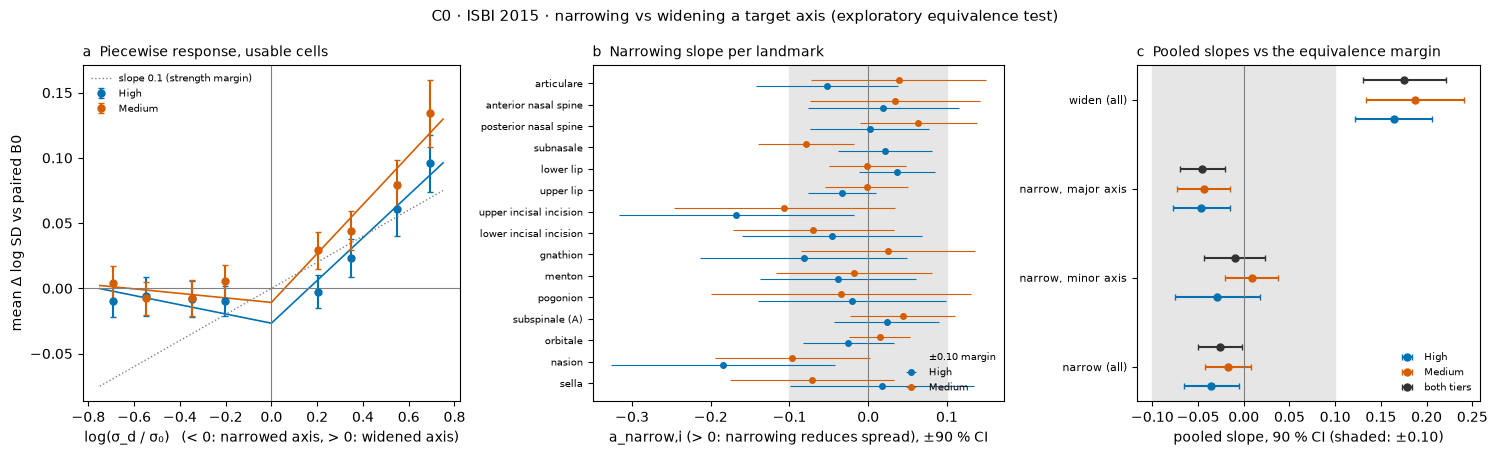

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.1, 1.2, 1]})
ax = axs[0]
for t, o in OBS.items():
    u = o[o.usable & o.landmark.isin(LM[LM.tier == t].landmark)]
    m = u.groupby("x").dlog_sd.agg(["mean", "std", "size"])
    ax.errorbar(m.index, m["mean"], yerr=1.96 * m["std"] / np.sqrt(m["size"]), fmt="o", color=COLORS[t], ms=5, capsize=2, label=t)
    g = LM[LM.tier == t]
    xx = np.linspace(-0.75, 0.75, 101)
    ax.plot(xx, g.c.mean() + g.a_wide.mean() * np.clip(xx, 0, None) + g.a_narrow.mean() * np.clip(xx, None, 0), color=COLORS[t], lw=1.2)
ax.plot([-0.75, 0.75], [-0.75 * 0.1, 0.75 * 0.1], color="0.5", ls=":", lw=1, label="slope 0.1 (strength margin)")
ax.axhline(0, color="0.5", lw=0.8); ax.axvline(0, color="0.5", lw=0.8)
ax.set_xlabel("log(σ_d / σ₀)   (< 0: narrowed axis, > 0: widened axis)"); ax.set_ylabel("mean Δ log SD vs paired B0")
ax.set_title("a  Piecewise response, usable cells", loc="left", fontsize=10); ax.legend(fontsize=7, frameon=False)

ax = axs[1]
order = both.index if len(both) else LM.landmark.unique()
names = [NAMES[l] for l in order]
for k, t in enumerate(TIERS):
    g = LM[LM.tier == t].set_index("landmark").reindex(order)
    yy = np.arange(len(order)) + (k - 0.5) * 0.3
    ax.errorbar(g.a_narrow, yy, xerr=1.645 * g.se_narrow, fmt="o", ms=4, color=COLORS[t], elinewidth=0.8, label=t)
ax.axvspan(-MARGIN_SLOPE, MARGIN_SLOPE, color="0.9", zorder=0, label="±0.10 margin")
ax.axvline(0, color="0.5", lw=0.8)
ax.set_yticks(np.arange(len(order))); ax.set_yticklabels(names, fontsize=7)
ax.set_xlabel("a_narrow,i (> 0: narrowing reduces spread), ±90 % CI")
ax.set_title("b  Narrowing slope per landmark", loc="left", fontsize=10); ax.legend(fontsize=7, frameon=False, loc="lower right")

ax = axs[2]
labels = {"a_narrow": "narrow (all)", "a_narrow_minor_axis": "narrow, minor axis", "a_narrow_major_axis": "narrow, major axis", "a_wide": "widen (all)"}
for k, t in enumerate(list(TIERS) + ["both tiers"]):
    for j, q in enumerate(labels):
        r = EQ[(EQ.tier == t) & (EQ.quantity == q)].iloc[0]
        y = j + (k - 1) * 0.22
        ax.errorbar(r["mean"], y, xerr=[[r["mean"] - r.ci90_low], [r.ci90_high - r["mean"]]], fmt="o", ms=5,
                    color=COLORS.get(t, "0.2"), capsize=2, label=t if j == 0 else None)
ax.axvspan(-MARGIN_SLOPE, MARGIN_SLOPE, color="0.9", zorder=0)
ax.axvline(0, color="0.5", lw=0.8)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(list(labels.values()), fontsize=8)
ax.set_xlabel("pooled slope, 90 % CI (shaded: ±0.10)")
ax.set_title("c  Pooled slopes vs the equivalence margin", loc="left", fontsize=10); ax.legend(fontsize=7, frameon=False)
fig.suptitle("C0 · ISBI 2015 · narrowing vs widening a target axis (exploratory equivalence test)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "narrowing_equivalence.png", dpi=150)